Vom face transformarea fisierului CSV intr-un tabel Python, pentru a putea fi procesat; se va face si citirea numarului de randuri si coloane si vom afisa primele 5 randuri. Coloane pe care trebuie sa o prezicem este cea de Churn.


In [1]:
# Proiectul 1 - Predictia plecarii clientilor (Telco Churn)

# incarcare fisier
import pandas as pd

url = "https://raw.githubusercontent.com/valentindragomir000-ai/proiect-1-ml/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Explorarea si Intelegerea Datelor

Tasks: dimensiunea, valorile lipsa, distributia tintei si 3 grafice.

In [2]:
## 1. Explorarea datelor

# Dimensiunea si tipul coloanelor = 7043 / 21
print(df.shape)
df.info()


(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [3]:
# Valori lipsa = 11
df.isna().sum()
(df["TotalCharges"] == " ").sum()

np.int64(11)

In [4]:
# Distributia tintei (cati clienti  au da/nu si sunt arate sub forma de proportii)
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True)

,proportion
Churn,
No,0.73463
Yes,0.26537


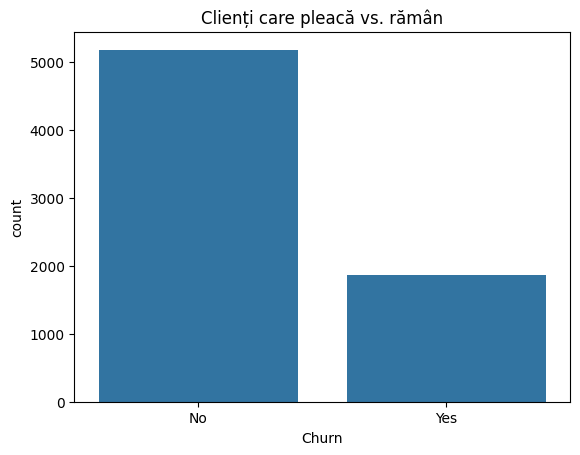

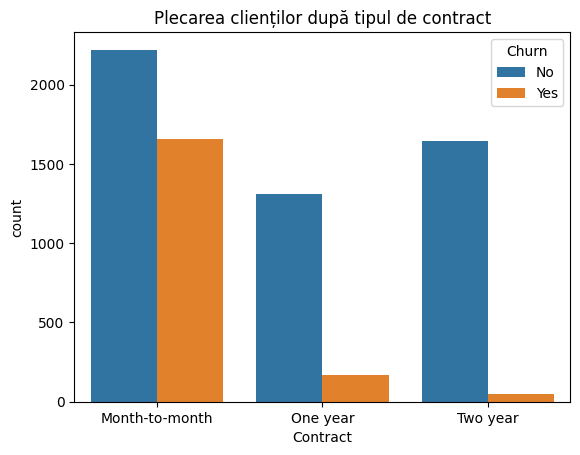

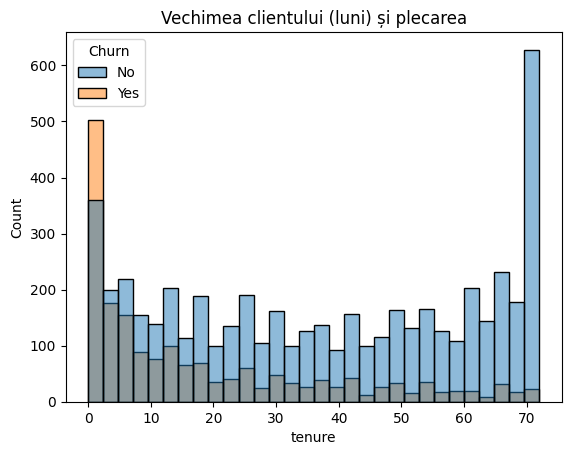

In [5]:
# Cele 3 grafice

# importare date
import matplotlib.pyplot as plt
import seaborn as sns

# Grafic 1 : cati clienti pleaca
sns.countplot(data=df, x="Churn")
plt.title("Clienți care pleacă vs. rămân")
plt.show()

# Grafic 2 : tipul de contract vs. plecare
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Plecarea clienților după tipul de contract")
plt.show()

# Grafic 3 : vechimea clientului vs. plecare
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Vechimea clientului (luni) și plecarea")
plt.show()

Curatarea datelor


In [6]:
## 2. Curatarea si pregatirea datelor
# transformare text in numar
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isna().sum()

# cele 11 lipsuri
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

# zero in locul valorilor lipsa
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# scoatem customerId
df = df.drop(columns=["customerID"])

# tinta -> 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df["Churn"].value_counts()

# verificare
df.info()

# total charge de tip float64 si churn de tip int64 si 20 de coloane pentru ca am renuntat la customerId

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Pregatirea pentru model

In [7]:
## Pregatirea pentru model

# separare linii tinta
X = df.drop(columns=["Churn"])
y = df["Churn"]


# transformare coloane text in coloane 0 si 1
X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.shape)
X.head()


# impartirea train/test; 80%-20%
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)


# scalare ; necesara pentru ca avem coloane cu numere mari (TotalCharges); fit_transform / transform: scaler-ul invata doar din train.
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])



(7043, 30)
(5634, 30) (1409, 30)


Baseline

In [8]:
# Baseline ; cu care vom compara modelul nostru (accuracy de 0.73 - clientii care raman, iar recall de 0.00 - clientii care pleaca)

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print(classification_report(y_test, y_pred_dummy, zero_division=0))

Accuracy: 0.7345635202271115
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



Modele : regresie logistica si random forest

In [10]:
# regresie logistica
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

print(classification_report(y_test, y_pred_lr))


# random forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

# verificare: invata sau memoreaza ?
print("RF pe train:", rf.score(X_train, y_train))
print("RF pe test: ", rf.score(X_test, y_test))
print("LR pe train:", log_reg.score(X_train_scaled, y_train))
print("LR pe test: ", log_reg.score(X_test_scaled, y_test))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.78      1409

RF pe train: 0.9980475683351083
RF pe test:  0.7927608232789212
LR pe train: 0.8058217962371317
LR pe test:  0.8062455642299503


Matricea de confuzie

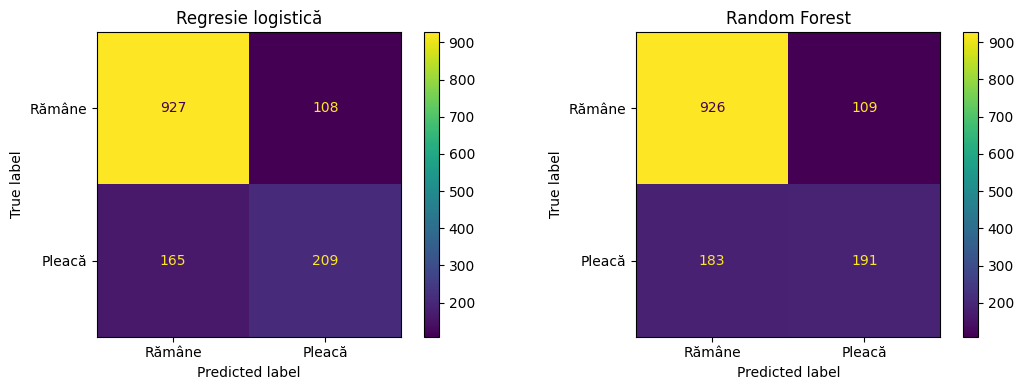

In [11]:
# matricea de confuzie
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, ax=axes[0], display_labels=["Rămâne", "Pleacă"]
)
axes[0].set_title("Regresie logistică")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, ax=axes[1], display_labels=["Rămâne", "Pleacă"]
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

Imbunatatiri

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Cei mai buni parametri: {'max_depth': 10, 'min_samples_leaf': 10}
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409

Train: 0.8013844515441959  Test: 0.759403832505323


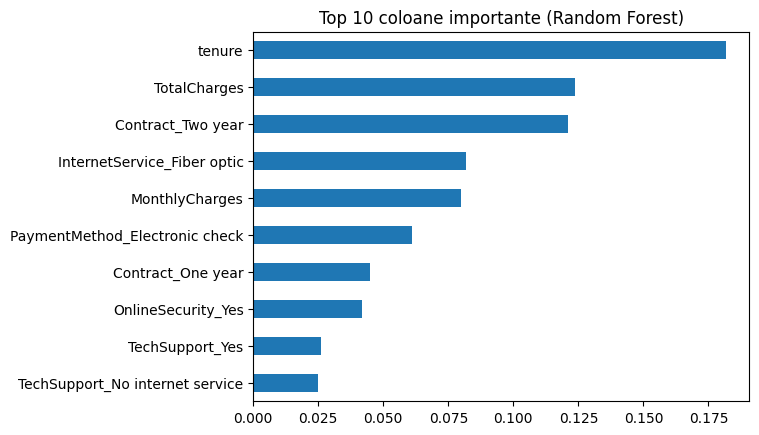

,Model,Precision,Recall,F1,Accuracy
0,Baseline,0.00,0.00,0.00,0.73
1,Regresie logistică,0.66,0.56,0.60,0.81
2,Random Forest,0.64,0.51,0.57,0.79
3,Regresie logistică (balanced),0.50,0.78,0.61,0.74
4,Random Forest (optimizat),0.53,0.78,0.63,0.76


In [12]:
# Regresie logistica "echilibrata" (balanced)
log_reg_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg_bal.fit(X_train_scaled, y_train)
y_pred_lr_bal = log_reg_bal.predict(X_test_scaled)

print(classification_report(y_test, y_pred_lr_bal))


# random forest iptimizat cu GridSearchCv
from sklearn.model_selection import GridSearchCV

parametri = {
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    parametri,
    scoring="f1",
    cv=5,
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Cei mai buni parametri:", grid.best_params_)
best_rf = grid.best_estimator_
y_pred_rf_best = best_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf_best))
print("Train:", best_rf.score(X_train, y_train), " Test:", best_rf.score(X_test, y_test))


# importanta coloanelor
importante = pd.Series(best_rf.feature_importances_, index=X_train.columns)
importante = importante.sort_values(ascending=False)

importante.head(10).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 coloane importante (Random Forest)")
plt.show()

# Tabel final cu toate modelele
from sklearn.metrics import precision_score, recall_score, f1_score

predictii = {
    "Baseline": y_pred_dummy,
    "Regresie logistică": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Regresie logistică (balanced)": y_pred_lr_bal,
    "Random Forest (optimizat)": y_pred_rf_best,
}

randuri = []
for nume, pred in predictii.items():
    randuri.append({
        "Model": nume,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    })

tabel = pd.DataFrame(randuri).round(2)
tabel